# Lecture 04 Practical: Regression : Predicting Continuous Outcomes

## Clinical question

Can baseline patient measurements help predict a **quantitative measure of diabetes disease progression one year later**?

This practical follows the same conceptual path as the lecture:

1. identify the features and continuous target;
2. begin with one predictor;
3. fit a linear relationship;
4. inspect predictions and residuals;
5. move from one predictor to many;
6. evaluate with MAE, RMSE and \(R^2\);
7. compare training performance with performance on unseen patients;
8. recognise underfitting and overfitting.

### Dataset

We use the public **Diabetes regression dataset** distributed with scikit-learn. It contains 442 patients, 10 baseline variables, and a quantitative measure of disease progression one year after baseline.

For interpretation, this notebook loads the **unscaled/raw feature values** (`scaled=False`) rather than scikit-learn's default standardized representation.

**Important:** the target is a quantitative research outcome from this historical dataset. It is not a diagnosis, probability, or direct clinical decision.

### References

- Efron B, Hastie T, Johnstone I, Tibshirani R. *Least Angle Regression*. **Annals of Statistics**. 2004;32(2):407–499. DOI: 10.1214/009053604000000067.
- James G, Witten D, Hastie T, Tibshirani R, Taylor J. *An Introduction to Statistical Learning: with Applications in Python*. Springer; 2023.
- Lever J, Krzywinski M, Altman N. *Model selection and overfitting*. **Nature Methods**. 2016;13:703–704. DOI: 10.1038/nmeth.3968.

The aim is not to obtain the highest possible score. The aim is to understand what regression learns, how prediction error is measured, and why evaluation on unseen patients matters.

## 0. Setup

Run this cell first. No internet connection is required once scikit-learn is installed because the dataset is bundled with the library.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["font.size"] = 11

RANDOM_STATE = 42

diabetes = load_diabetes(as_frame=True, scaled=False)
df = diabetes.frame.copy()

# Clearer labels for this practical
df = df.rename(columns={
    "bp": "blood_pressure",
    "s1": "serum_s1",
    "s2": "serum_s2",
    "s3": "serum_s3",
    "s4": "serum_s4",
    "s5": "serum_s5",
    "s6": "serum_s6",
    "target": "progression"
})

print(f"Patients: {len(df)}")
print(f"Columns: {df.shape[1]}")
df.head()

Patients: 442
Columns: 11


,age,sex,bmi,blood_pressure,serum_s1,serum_s2,serum_s3,serum_s4,serum_s5,serum_s6,progression
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


In [2]:
def check_value(name, value, expected, atol=1e-6):
    if value is None:
        print(f"{name}: not answered yet.")
        return
    try:
        ok = np.isclose(float(value), float(expected), atol=atol)
    except Exception:
        ok = False
    print(f"{name}: " + ("Correct." if ok else "Not quite. Revisit the calculation and try again."))

def check_text(name, value, accepted):
    if value is None or str(value).strip() == "":
        print(f"{name}: not answered yet.")
        return
    normalized = str(value).strip().lower()
    ok = normalized in {str(x).strip().lower() for x in accepted}
    print(f"{name}: " + ("Correct." if ok else "Not quite. Re-read the question and try again."))

def check_choice(name, value, expected):
    if value is None:
        print(f"{name}: not answered yet.")
        return
    print(f"{name}: " + ("Correct." if value == expected else "Not quite. Inspect the evidence again."))

## 1. From a clinical question to a regression problem

Inspect the first rows and the column names.

**Questions**

1. What does one row represent?
2. Which variable is the target?
3. Is this a regression or classification problem?
4. Why?

In [3]:
display(df.head())
print(df.columns.tolist())

# Complete these answers.
one_row_represents = "one patient (baseline measurements plus progression one year later)"
target_name = "progression"
problem_type = "regression"

# Check-up
check_text("Target", target_name, ["progression"])
check_text("Problem type", problem_type, ["regression"])

,age,sex,bmi,blood_pressure,serum_s1,serum_s2,serum_s3,serum_s4,serum_s5,serum_s6,progression
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


['age', 'sex', 'bmi', 'blood_pressure', 'serum_s1', 'serum_s2', 'serum_s3', 'serum_s4', 'serum_s5', 'serum_s6', 'progression']
Target: Correct.
Problem type: Correct.


### Answers – Section 1

1. **One row** represents one patient: their baseline measurements plus their disease progression one year later.
2. **Target:** `progression`, the quantitative measure of disease progression after one year. The other 10 columns are the features.
3. **Problem type:** regression.
4. **Why:** the target is a continuous numerical value (range 25–346), not a category, so the model has to predict a number.

**Think before continuing:** A continuous target tells us the *type* of prediction problem. It does not tell us whether the prediction will be clinically useful.

## 2. Begin with one predictor

We will first ask whether **BMI at baseline** contains information about later disease progression.

Make a scatter plot with BMI on the horizontal axis and progression on the vertical axis. Each dot should represent one patient.

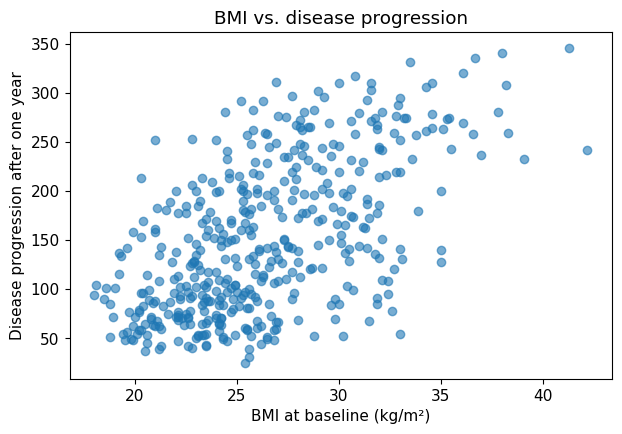

In [4]:
plt.scatter(df["bmi"], df["progression"], alpha=0.6)
plt.xlabel("BMI at baseline (kg/m²)")
plt.ylabel("Disease progression after one year")
plt.title("BMI vs. disease progression")
plt.show()

**Question:** Describe the relationship without using causal language. Is it positive, negative, or absent? Is it perfectly linear?

In [5]:
relationship_direction = "positive"  # "positive", "negative", or "absent"

check_text("Direction of association", relationship_direction,
           ["positive", "positive association", "positive relationship"])

Direction of association: Correct.


**Answer:** There is a **positive association**: patients with higher BMI at baseline tend to have higher progression values one year later. The relationship is far from perfectly linear – the points are widely scattered around the trend, and patients with the same BMI can have very different outcomes.

## 3. Fit a simple linear regression

For one predictor, the model has the form

\[
\hat{y}=b_0+b_1x
\]

Fit a model using BMI only. Then record the intercept and slope.

In [6]:
X_bmi = df[["bmi"]]
y = df["progression"]

bmi_model = LinearRegression().fit(X_bmi, y)
bmi_intercept = bmi_model.intercept_
bmi_slope = bmi_model.coef_[0]

print(f"Intercept: {bmi_intercept:.2f}")
print(f"BMI slope: {bmi_slope:.2f}")

Intercept: -117.77
BMI slope: 10.23


In [7]:
# Check-up: the tolerance allows for tiny numerical differences.
check_value("Intercept", bmi_intercept, -117.77336656656527, atol=1e-6)
check_value("BMI slope", bmi_slope, 10.233127870100687, atol=1e-6)

Intercept: Correct.
BMI slope: Correct.


### Interpret the slope

Complete the sentence in your own words:

> Among these data, a one-unit increase in BMI corresponds to a change of approximately ______ units in the model's predicted progression.

**Important:** this coefficient describes a predictive association. It does not establish that changing BMI would cause the outcome to change by that amount.

**Answer:** Among these data, a one-unit increase in BMI corresponds to a change of approximately **+10.23 units** in the model's predicted progression.

This is a predictive association, not a causal effect: it does not mean that lowering a patient's BMI by one unit would reduce their progression by 10.23 units.

## 4. Prediction and residuals

Use the fitted BMI model to predict all 442 observed outcomes.

For each patient:

\[
e_i = y_i-\hat{y}_i
\]

A positive residual means the observed outcome was higher than the model predicted.

In [8]:
bmi_predictions = bmi_model.predict(X_bmi)
bmi_residuals = y - bmi_predictions  # observed minus predicted
bmi_mae = mean_absolute_error(y, bmi_predictions)
bmi_rmse = np.sqrt(mean_squared_error(y, bmi_predictions))
bmi_r2 = r2_score(y, bmi_predictions)

print(f"MAE: {bmi_mae:.2f}  RMSE: {bmi_rmse:.2f}  R²: {bmi_r2:.3f}")

MAE: 51.80  RMSE: 62.37  R²: 0.344


In [9]:
check_value("BMI model MAE", bmi_mae, 51.798627639533656, atol=1e-6)
check_value("BMI model RMSE", bmi_rmse, 62.37352471570989, atol=1e-6)
check_value("BMI model R²", bmi_r2, 0.3439237602253803, atol=1e-6)

BMI model MAE: Correct.
BMI model RMSE: Correct.
BMI model R²: Correct.


### Inspect the errors

Create a residual plot: predicted progression on the horizontal axis and residual on the vertical axis. Add a horizontal line at zero.

**Look for:** curvature, changing spread, isolated observations, or other structure. A summary metric cannot show these patterns.

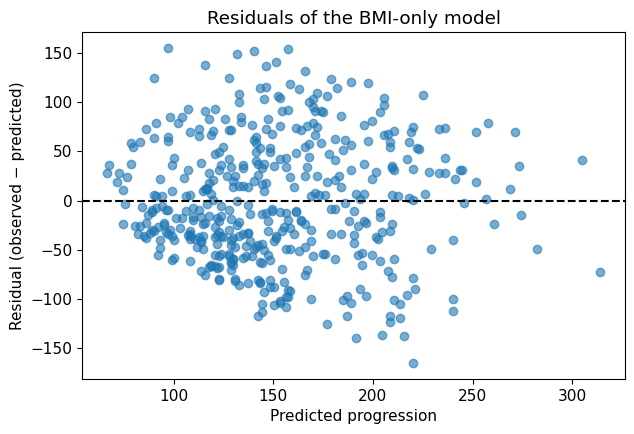

In [10]:
plt.scatter(bmi_predictions, bmi_residuals, alpha=0.6)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Predicted progression")
plt.ylabel("Residual (observed − predicted)")
plt.title("Residuals of the BMI-only model")
plt.show()

**What the residual plot shows:** The residuals scatter around zero without clear curvature, so a straight line captures the main trend. The spread is large (residuals roughly from −165 to +155) and not constant: it is narrower at low predicted values, where residuals are bounded below because progression cannot fall below about 25 (visible as a diagonal lower edge), and widest at mid-range predictions. A few patients with high predictions (> 250) are isolated points. Overall, BMI alone leaves much of the variation in progression unexplained.

## 5. From one predictor to many

A patient's outcome is unlikely to depend on BMI alone. Fit a multiple linear regression using all 10 baseline features.

\[
\hat{y}=b_0+b_1x_1+\cdots+b_px_p
\]

Compare the in-sample MAE, RMSE and \(R^2\) with the BMI-only model.

In [11]:
X_all = df.drop(columns="progression")

full_model = LinearRegression().fit(X_all, y)
full_predictions = full_model.predict(X_all)
full_mae = mean_absolute_error(y, full_predictions)
full_rmse = np.sqrt(mean_squared_error(y, full_predictions))
full_r2 = r2_score(y, full_predictions)

pd.DataFrame({
    "MAE": [bmi_mae, full_mae],
    "RMSE": [bmi_rmse, full_rmse],
    "R²": [bmi_r2, full_r2],
}, index=["BMI only", "All 10 features"]).round(3)

,MAE,RMSE,R²
BMI only,51.799,62.374,0.344
All 10 features,43.277,53.476,0.518


In [12]:
check_value("Full model MAE", full_mae, 43.27745202531505, atol=1e-6)
check_value("Full model RMSE", full_rmse, 53.47612876402657, atol=1e-6)
check_value("Full model R²", full_r2, 0.5177484222203498, atol=1e-6)

Full model MAE: Correct.
Full model RMSE: Correct.
Full model R²: Correct.


**Question:** Does the better fit prove that every coefficient is clinically important or causal?

Write `yes` or `no`.

In [13]:
coefficients_are_causal = "no"
check_text("Causal interpretation", coefficients_are_causal, ["no"])

Causal interpretation: Correct.


**Comparison with the BMI-only model:** Using all 10 features improves the in-sample fit: MAE drops from ≈51.8 to ≈43.3, RMSE from ≈62.4 to ≈53.5, and R² rises from ≈0.34 to ≈0.52. The model therefore explains more of the variation in progression, but about half of the variance remains unexplained. These are in-sample metrics measured on the same patients used for fitting, so they are optimistic.

The coefficients below are on the raw (unscaled) feature scales, so their sizes are **not** directly comparable, and correlated features (e.g. serum_s1/s2) can share or swap predictive information. They describe predictive associations, not causal effects.

In [14]:
pd.Series(full_model.coef_, index=X_all.columns, name="coefficient").round(2).to_frame()

,coefficient
age,-0.04
sex,-22.86
bmi,5.60
blood_pressure,1.12
serum_s1,-1.09
serum_s2,0.75
serum_s3,0.37
serum_s4,6.53
serum_s5,68.48
serum_s6,0.28


## 6. The central question: will it work for unseen patients?

Performance on the same patients used to fit the model is optimistic as an estimate of generalisation.

We will now hold out 30% of the patients. The model is fitted only on the training patients. The test patients do not influence fitting.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y, test_size=0.30, random_state=RANDOM_STATE
)

split_model = LinearRegression().fit(X_train, y_train)
train_pred = split_model.predict(X_train)
test_pred = split_model.predict(X_test)

train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))
test_mae = mean_absolute_error(y_test, test_pred)
test_r2 = r2_score(y_test, test_pred)

print(f"Training RMSE: {train_rmse:.2f}  Test RMSE: {test_rmse:.2f}")
print(f"Test MAE: {test_mae:.2f}  Test R²: {test_r2:.3f}")

Training RMSE: 54.07  Test RMSE: 53.12
Test MAE: 41.92  Test R²: 0.477


In [16]:
check_value("Training RMSE", train_rmse, 54.07445218467442, atol=1e-6)
check_value("Test RMSE", test_rmse, 53.120156070942706, atol=1e-6)
check_value("Test MAE", test_mae, 41.91937845679274, atol=1e-6)
check_value("Test R²", test_r2, 0.4772897164322617, atol=1e-6)

Training RMSE: Correct.
Test RMSE: Correct.
Test MAE: Correct.
Test R²: Correct.


**Interpretation question:** Which number is the better estimate of how this fitted model performs on patients it did not learn from: training RMSE or test RMSE?

In [17]:
better_generalisation_estimate = "test RMSE"  # "training RMSE" or "test RMSE"
check_text("Generalisation estimate", better_generalisation_estimate,
           ["test rmse", "test"])

Generalisation estimate: Correct.


**Interpretation:** Training RMSE (≈54.1) and test RMSE (≈53.1) are very similar, so this linear model shows no sign of overfitting – with only 10 features and ~300 training patients it is not very flexible. The **test RMSE** is the better estimate of generalisation because the test patients were not used for fitting. That the test RMSE is slightly lower is due to chance in this particular split, not because the model works better on new patients.

## 7. Underfitting and overfitting

To make model flexibility visible, we will return to one predictor, BMI, and compare polynomial regression models of increasing degree.

This is a teaching experiment, not a recommendation to model diabetes progression with high-degree polynomials.

We use the same training/test split for every degree. For each model, calculate training and test RMSE.

In [18]:
X1_train, X1_test, y1_train, y1_test = train_test_split(
    df[["bmi"]], y, test_size=0.30, random_state=RANDOM_STATE
)

degrees = range(1, 13)
results = []

for degree in degrees:
    model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
    model.fit(X1_train, y1_train)
    train_rmse_d = np.sqrt(mean_squared_error(y1_train, model.predict(X1_train)))
    test_rmse_d = np.sqrt(mean_squared_error(y1_test, model.predict(X1_test)))
    results.append([degree, train_rmse_d, test_rmse_d])

complexity = pd.DataFrame(results, columns=["degree", "train_rmse", "test_rmse"])
complexity

,degree,train_rmse,test_rmse
0,1,62.445615,62.329261
1,2,62.392800,62.492253
2,3,62.392686,62.473742
3,4,62.302717,62.956680
4,5,62.252836,62.272659
5,6,62.188772,61.709850
6,7,62.207943,61.736653
7,8,62.216327,61.851732
8,9,62.197425,62.179041
9,10,62.143402,63.002748


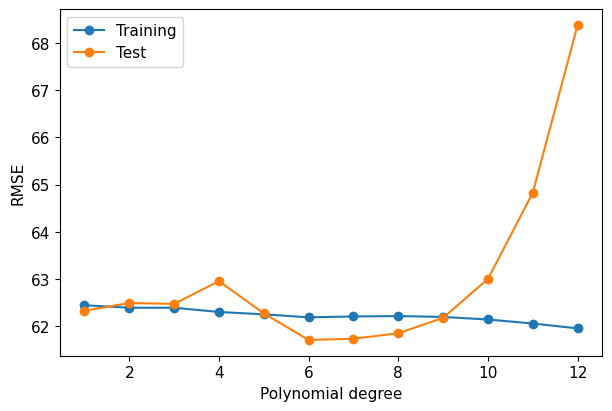

In [19]:
# Plot once the table above is complete.
if len(complexity) > 0:
    plt.plot(complexity["degree"], complexity["train_rmse"], marker="o", label="Training")
    plt.plot(complexity["degree"], complexity["test_rmse"], marker="o", label="Test")
    plt.xlabel("Polynomial degree")
    plt.ylabel("RMSE")
    plt.legend()
    plt.show()

**Questions**

1. What happens to training error as flexibility increases?
2. Does test error behave in the same way?
3. Which degree has the lowest test RMSE in this particular split?

In [20]:
best_degree = int(complexity.loc[complexity["test_rmse"].idxmin(), "degree"])
print(f"Lowest test RMSE at degree {best_degree}")

# Check-up
check_value("Degree with lowest test RMSE", best_degree, 6, atol=0)

Lowest test RMSE at degree 6
Degree with lowest test RMSE: Correct.


### Answers – Section 7

1. **Training error:** training RMSE generally decreases as the polynomial degree increases (≈62.4 at degree 1 to ≈62.0 at degree 12), because a more flexible model can follow the training patients more closely. The decline is not perfectly monotonic due to small numerical effects, but the trend is downward.
2. **Test error:** no. Test RMSE improves only slightly up to a moderate degree and then rises sharply (≈68.4 at degree 12). Training RMSE keeps falling because the extra flexibility is used to fit noise in the training data; that noise does not repeat in new patients, so the high-degree models generalise worse – this is **overfitting**. Very simple models that miss real structure would be **underfitting**; here even degree 1 is close to the best, so BMI alone carries only limited signal.
3. **Lowest test RMSE:** degree **6** (test RMSE ≈ 61.7), read from the `complexity` table above. The differences between degrees 1–9 are small, so this choice is specific to this one split and should not be over-interpreted.

## 8. Final interpretation

Complete the five statements in plain language.

1. Regression is appropriate when the target is ...
2. A residual is ...
3. MAE and RMSE differ because ...
4. Overfitting means ...
5. A predictive relationship does not establish ...

Keep each answer to one or two sentences.

### Answers – Section 8

1. **Regression is appropriate when the target is** a continuous, quantitative value (here the progression score), so the model has to predict a number rather than a class.
2. **A residual is** the difference between the observed outcome and the model's prediction for the same patient (e = y − ŷ); a positive residual means the model under-predicted.
3. **MAE and RMSE differ because** MAE averages the absolute errors, whereas RMSE squares the errors before averaging, so large errors are penalised more strongly and RMSE is always ≥ MAE.
4. **Overfitting means** the model is so flexible that it learns noise specific to the training patients: training error keeps falling, but prediction error on unseen patients rises, i.e. generalisation gets worse.
5. **A predictive relationship does not establish** causation: a feature that helps predict progression does not mean that changing that feature would change the outcome, because the association may be due to confounding or other factors.

## 9. Take-home check

Before leaving, make sure you can explain these ideas without code:

- why this is a regression problem;
- what a regression coefficient means;
- the difference between an observed outcome and a prediction;
- what MAE, RMSE and \(R^2\) tell us;
- why residual plots remain useful;
- why training performance is not the goal;
- why prediction is not causation.

### A final caution

The held-out test set in this notebook is a simple teaching device. In a real healthcare AI study, model selection, preprocessing, repeated measurements, temporal structure, external validation and leakage require more careful design. We return to these issues in **Lecture 08: Developing & Evaluating Healthcare AI**.